In [1]:
import numpy as np
from matplotlib import pyplot as plt
from numba import njit, prange

## Unique Points

This portion of the notebook generates some RabitQ 2 bit grids, i.e. [0, 1, 2, 3].

It then shifts them by -1.5 in each dimension, as per the paper.

Here, we measure how many 'unique points' (i.e. those without another point which maps to the same point on the hypersphere) on the hypersphere this mapping results in as d increases

In [2]:
vals = [0, 1, 2, 3]
MAX_VAL = 3

In [3]:
def make_grid(dimensions):
    grids= []
    current = [0 for _ in range(dimensions)]
    
    return np.array(extend_grid(grids, current)) - 1.5
    
def extend_grid(grids, current):
    
    finished = False
    
    
    while not finished:
        grids.append(current)
        
        if np.any(current != MAX_VAL):
            current = get_next_grid(current)                
        else:
            finished = True
            
    return grids
        
def get_next_grid(vec):
   index = 0
   finished = False
   
   new_vec = np.copy(vec)
   
   while not finished:
        new_vec[index] += 1
        
        if new_vec[index] == MAX_VAL + 1 and index < len(new_vec):
            new_vec[index] = 0
        else:
            return new_vec
            
        index += 1
    

In [4]:
print(make_grid(2))

[[-1.5 -1.5]
 [-0.5 -1.5]
 [ 0.5 -1.5]
 [ 1.5 -1.5]
 [-1.5 -0.5]
 [-0.5 -0.5]
 [ 0.5 -0.5]
 [ 1.5 -0.5]
 [-1.5  0.5]
 [-0.5  0.5]
 [ 0.5  0.5]
 [ 1.5  0.5]
 [-1.5  1.5]
 [-0.5  1.5]
 [ 0.5  1.5]
 [ 1.5  1.5]]


In [5]:


def count_unique_rows(a, rtol=1e-5, atol=1e-8):
    reps = []

    for row in np.asarray(a):
        if not reps or not np.any(
            np.all(np.isclose(reps, row, rtol=rtol, atol=atol), axis=1)
        ):
            reps.append(row)

    return len(reps)

def count_unique(n):    
    grid = make_grid(n)
    normalised_grid = grid / np.linalg.norm(grid, axis=1, keepdims=True)
    return count_unique_rows(normalised_grid)

def frac_unique(n):
    return count_unique(n) / (4 ** n)

In [6]:
frac_unique(3)

0.875

In [7]:
ds = [i for i in range(2, 6)]
fracs = [frac_unique(d) for d in ds]

Text(0, 0.5, 'Fraction Unique')

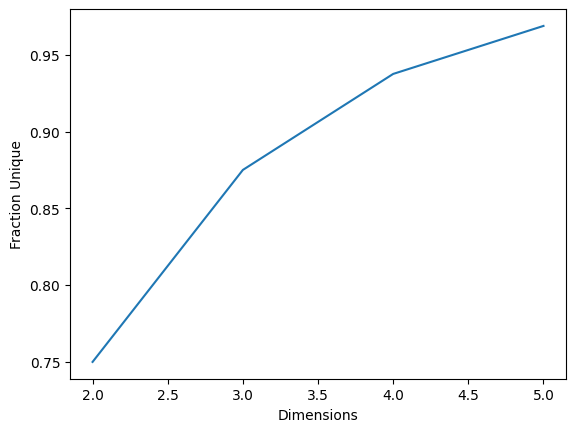

In [8]:
plt.plot(ds, fracs)
plt.xlabel("Dimensions")
plt.ylabel("Fraction Unique")

## Cell Sizes
We know that EVPs have equally sized voranoi cells.

We measure the voranoi cell sizes of codebook vectors via Monte-Carlo sampling here.

In [9]:
import numpy as np
from numba import njit, prange, get_num_threads, get_thread_id
from numba_progress import ProgressBar


@njit(
    parallel=True,
    boundscheck=False,
    nogil=True,
)
def monte_carlo(grid, progress_proxy, reps=1_000):
    n_grid = grid.shape[0]
    dim = grid.shape[1]

    n_threads = get_num_threads()

    # Each thread gets its own histogram to avoid race conditions.
    thread_bins = np.zeros(
        (n_threads, n_grid),
        dtype=np.int64,
    )

    for i in prange(reps):
        tid = get_thread_id()

        # Random direction.
        #
        # No need to normalize it: multiplying all dot products
        # by the same positive factor doesn't affect argmax.
        point = np.random.normal(0.0, 1.0, dim)

        # Find grid vector with largest dot product.
        #
        # Do this manually rather than:
        #     scores = grid @ point
        #     closest_id = np.argmax(scores)
        #
        # to avoid allocating `scores` every iteration.
        best_id = 0
        best_score = -np.inf

        for k in range(n_grid):
            score = 0.0

            for j in range(dim):
                score += grid[k, j] * point[j]

            if score > best_score:
                best_score = score
                best_id = k

        thread_bins[tid, best_id] += 1

        progress_proxy.update(1)

    # Combine the per-thread histograms.
    monte_carlo_bins = np.zeros(n_grid, dtype=np.int64)

    for t in range(n_threads):
        for k in range(n_grid):
            monte_carlo_bins[k] += thread_bins[t, k]

    return monte_carlo_bins

In [10]:
reps = 10_000_000

dim = 4
grid = make_grid(dim)

# Use this if you're comparing directions / angular closeness
normed_grid = grid / np.linalg.norm(grid, axis=1, keepdims=True)

with ProgressBar(total=reps) as progress:
    bins = monte_carlo(
        normed_grid,
        progress,
        reps,
    )

  0%|          | 0/10000000 [00:00<?, ?it/s]

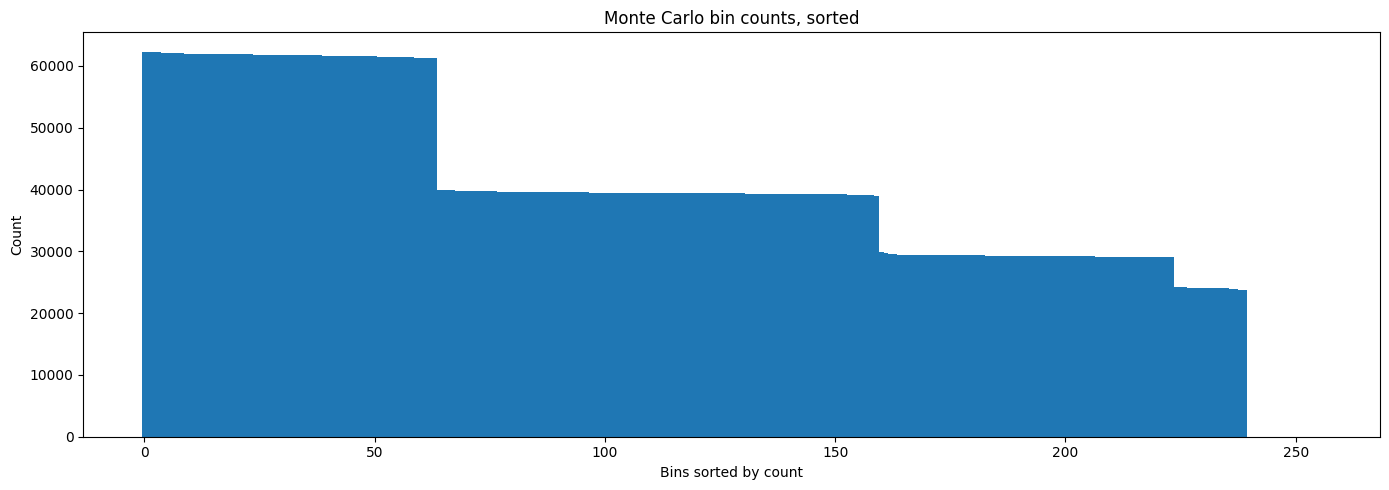

In [11]:
import matplotlib.pyplot as plt
import numpy as np

sorted_bins = np.sort(bins)[::-1]  # largest to smallest

fig, ax = plt.subplots(figsize=(14, 5))

x = np.arange(len(sorted_bins))
ax.bar(x, sorted_bins, width=1.0)

ax.set_xlabel("Bins sorted by count")
ax.set_ylabel("Count")
ax.set_title("Monte Carlo bin counts, sorted")

plt.tight_layout()
plt.show()

In [12]:
reps = 10_000_000

dim = 6
grid = make_grid(dim)

# Use this if you're comparing directions / angular closeness
normed_grid = grid / np.linalg.norm(grid, axis=1, keepdims=True)

with ProgressBar(total=reps) as progress:
    bins = monte_carlo(
        normed_grid,
        progress,
        reps,
    )

  0%|          | 0/10000000 [00:00<?, ?it/s]

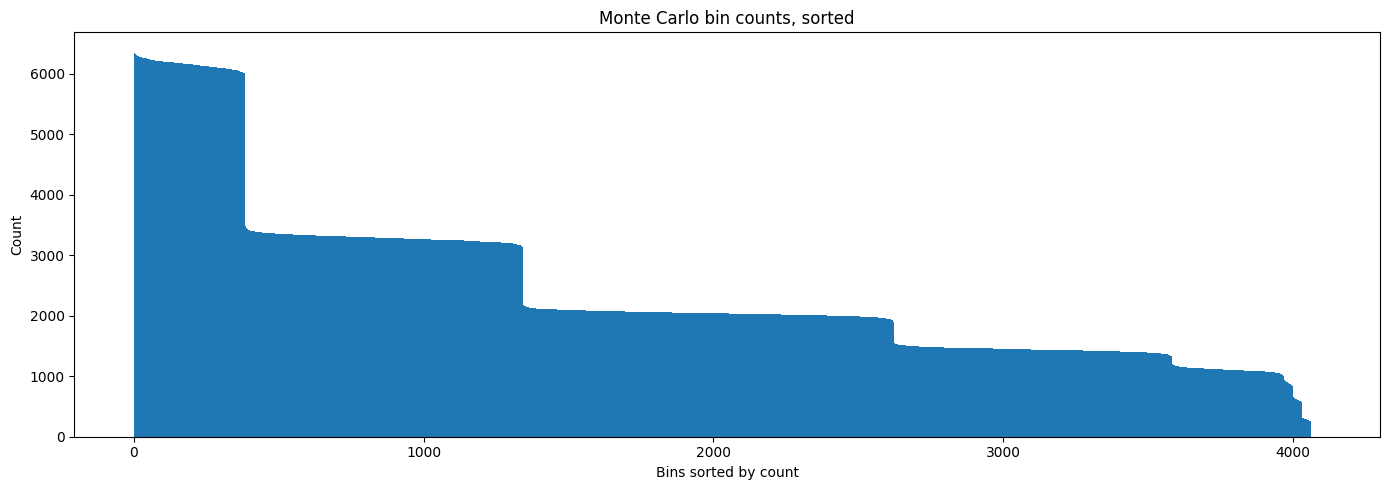

In [13]:
import matplotlib.pyplot as plt
import numpy as np

sorted_bins = np.sort(bins)[::-1]  # largest to smallest

fig, ax = plt.subplots(figsize=(14, 5))

x = np.arange(len(sorted_bins))
ax.bar(x, sorted_bins, width=1.0)

ax.set_xlabel("Bins sorted by count")
ax.set_ylabel("Count")
ax.set_title("Monte Carlo bin counts, sorted")

plt.tight_layout()
plt.show()

In [14]:
probs = np.sort(bins / np.sum(bins))[::-1]
print(np.sum(probs))

probs_nonzero = probs[probs > 0]
entropy = -np.sum(probs_nonzero * np.log2(probs_nonzero))
print(entropy)

1.0
11.780843897354682


## `{x, d}` Equi-Voronoi polytope estimator

A vertex of the `{x, d}` EVP has exactly `x` non-zero coordinates, each equal to `-1` or `1`. Because every vertex has norm $\sqrt{x}$, the nearest vertex to a direction is obtained by selecting the `x` coordinates with the largest absolute values and copying their signs.

The estimator below samples Gaussian directions (which are uniform after projection onto the sphere) and counts their nearest EVP vertices. It works in batches and never constructs the full codebook. Bins use a stable combinadic rank for the selected coordinate subset followed by `x` sign bits.

In [15]:
import math


def evp_vertex_count(x, d):
    """Return the number of vertices in the {x, d} EVP."""
    if not isinstance(x, (int, np.integer)) or not isinstance(d, (int, np.integer)):
        raise TypeError("x and d must be integers")

    x, d = int(x), int(d)
    if d < 1 or not 1 <= x <= d:
        raise ValueError("expected d >= 1 and 1 <= x <= d")

    return math.comb(d, x) * (1 << x)


def monte_carlo_evp(
    x,
    d,
    reps=1_000,
    *,
    batch_size=10_000,
    rng=None,
    progress=None,
    max_histogram_bytes=512 * 1024**2,
):
    """Estimate the spherical Voronoi-cell sizes of the {x, d} EVP.

    Parameters
    ----------
    x, d : int
        Number of non-zero coordinates and ambient dimension.
    reps : int
        Number of uniformly distributed directions to sample.
    batch_size : int
        Samples processed at once. Lower this to reduce temporary memory.
    rng : None, int, or numpy.random.Generator
        Random generator or seed.
    progress : optional
        Object with an update(number_of_samples) method.
    max_histogram_bytes : int or None
        Refuse unexpectedly large dense histograms by default. Set to None
        to disable the guard.

    Returns
    -------
    numpy.ndarray
        Counts for all comb(d, x) * 2**x vertices. Divide by reps for
        estimated cell probabilities.
    """
    n_vertices = evp_vertex_count(x, d)
    x, d = int(x), int(d)

    if not isinstance(reps, (int, np.integer)) or reps < 1:
        raise ValueError("reps must be a positive integer")
    if not isinstance(batch_size, (int, np.integer)) or batch_size < 1:
        raise ValueError("batch_size must be a positive integer")
    if n_vertices > np.iinfo(np.int64).max:
        raise ValueError("the EVP has too many vertices for int64 bin IDs")

    histogram_bytes = n_vertices * np.dtype(np.int64).itemsize
    if max_histogram_bytes is not None and histogram_bytes > max_histogram_bytes:
        raise MemoryError(
            f"dense histogram needs {histogram_bytes / 1024**2:.1f} MiB; "
            "increase max_histogram_bytes or use smaller x/d"
        )

    reps, batch_size = int(reps), int(batch_size)
    if rng is None or isinstance(rng, (int, np.integer)):
        rng = np.random.default_rng(rng)
    if not hasattr(rng, "standard_normal"):
        raise TypeError("rng must be a seed or a NumPy Generator")

    # Pascal-table lookup used to rank each sorted coordinate subset:
    # rank({c_0 < ... < c_(x-1)}) = sum(comb(c_i, i + 1)).
    choose = np.zeros((d, x + 1), dtype=np.int64)
    for n in range(d):
        for k in range(min(n, x) + 1):
            choose[n, k] = math.comb(n, k)

    sign_weights = np.left_shift(
        np.int64(1), np.arange(x, dtype=np.int64)
    )
    bins = np.zeros(n_vertices, dtype=np.int64)

    for start in range(0, reps, batch_size):
        current_batch_size = min(batch_size, reps - start)
        points = rng.standard_normal((current_batch_size, d))

        # Normalising points is unnecessary: a positive scale factor does
        # not change which equal-norm EVP vertex has the largest dot product.
        selected = np.argpartition(
            np.abs(points), d - x, axis=1
        )[:, d - x:]
        selected.sort(axis=1)
        selected_values = np.take_along_axis(points, selected, axis=1)

        subset_ranks = np.zeros(current_batch_size, dtype=np.int64)
        for i in range(x):
            subset_ranks += choose[selected[:, i], i + 1]

        sign_codes = (
            (selected_values > 0).astype(np.int64) * sign_weights
        ).sum(axis=1)
        bin_ids = subset_ranks * (1 << x) + sign_codes
        bins += np.bincount(bin_ids, minlength=n_vertices)

        if progress is not None:
            progress.update(current_batch_size)

    return bins

In [ ]:
# Example: estimate the cell probabilities of the {2, 8} EVP.
x = 4
dim = 8
reps = 10_000_000

with ProgressBar(total=reps) as progress:
    evp_bins = monte_carlo_evp(
        x,
        dim,
        reps,
        rng=0,
        progress=progress,
    )

evp_probs = evp_bins / reps
expected_prob = 1 / evp_vertex_count(x, dim)

print(f"vertices: {len(evp_bins):,}")
print(f"expected probability per cell: {expected_prob:.6g}")
print(f"mean estimated probability: {evp_probs.mean():.6g}")
print(f"largest absolute error: {np.max(np.abs(evp_probs - expected_prob)):.6g}")

  0%|          | 0/10000000 [00:00<?, ?it/s]

vertices: 160
expected probability per cell: 0.00625
mean estimated probability: 0.00625
largest absolute error: 8.19e-05


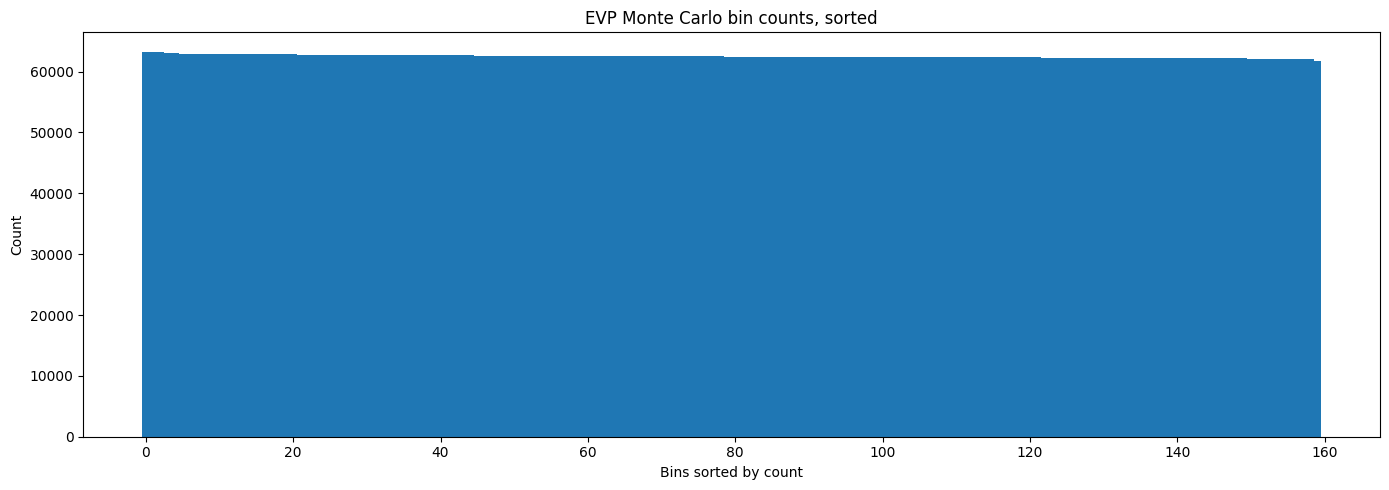

In [23]:
sorted_evp_bins = np.sort(evp_bins)[::-1]  # largest to smallest

fig, ax = plt.subplots(figsize=(14, 5))

x = np.arange(len(sorted_evp_bins))
ax.bar(x, sorted_evp_bins, width=1.0)

ax.set_xlabel("Bins sorted by count")
ax.set_ylabel("Count")
ax.set_title("EVP Monte Carlo bin counts, sorted")

plt.tight_layout()
plt.show()

In [24]:
probs = np.sort(evp_bins / np.sum(evp_bins))[::-1]
print(np.sum(probs))

probs_nonzero = probs[probs > 0]
entropy = -np.sum(probs_nonzero * np.log2(probs_nonzero))
print(entropy)

1.0
7.32191626908369
